In [ ]:
# Pickle the list
with open("human_cohort2_60m_32_gene_corrected_read_depth_nonzero_mean_None_gene_corrected_read_depth_None_shifted_log_knn_10_train.pkl", "rb") as f:
    train = pickle.load(f)

with open("human_cohort2_60m_32_gene_corrected_read_depth_nonzero_mean_None_gene_corrected_read_depth_None_shifted_log_knn_10_test.pkl", "rb") as f:
    test = pickle.load(f)

with open("human_cohort2_60m_32_None_None_None_gene_corrected_read_depth_None_shifted_log_knn_10_train.pkl", "rb") as f:
    new_train = pickle.load(f)

with open("human_cohort2_60m_32_None_None_None_gene_corrected_read_depth_None_shifted_log_knn_10_test.pkl", "rb") as f:
    new_test = pickle.load(f)

print(len(train))
print(len(test))
print(len(new_train))
print(len(new_test))

train_matches = set(train).intersection(new_train)
print(len(train_matches))
test_matches = set(test).intersection(new_test)
print(len(test_matches))

train_differences = []
for i in range(len(train)):
    if train[i] != new_train[i]:
        train_differences.append((i, train[i], new_train[i]))
print(train_differences)
print(len(differences))

test_differences = []
for i in range(len(test)):
    if test[i] != new_test[i]:
        test_differences.append((i, test[i], new_test[i]))
print(test_differences[-10:])

In [2]:
import scanpy as sc
adata = sc.read_h5ad(/adata_batch0.h5ad')

In [10]:
import os

'1000_batch27_0'

In [19]:
for subdir, _, files in os.walk('/lustre/scratch126/cellgen/team361/DATASETS/silver/xhb1002-AT9-6b_1p'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad'):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)
            print(file_path)
            print(adata.obs['cell_id'].values[0])
            #print(adata.obs['sample'].unique())
            print(adata.uns['batch'])
            print("================")

/lustre/scratch126/cellgen/team361/DATASETS/silver/xhb1002-AT9-6b_1p/AT9-BRA-4-FO-2-S38__filt_cells_filt_genes_raw_log1pnorm_counts.h5ad
1002_batch3_0
batch3
/lustre/scratch126/cellgen/team361/DATASETS/silver/xhb1002-AT9-6b_1p/AT9-BRA-4-FO-4-S45-i__filt_cells_filt_genes_raw_log1pnorm_counts.h5ad
1002_batch15_0
batch15
/lustre/scratch126/cellgen/team361/DATASETS/silver/xhb1002-AT9-6b_1p/AT9-BRA-5-FO-4-S52_ii__filt_cells_filt_genes_raw_log1pnorm_counts.h5ad
1002_batch27_0
batch27
/lustre/scratch126/cellgen/team361/DATASETS/silver/xhb1002-AT9-6b_1p/AT9-BRA-4-FO-2__filt_cells_filt_genes_raw_log1pnorm_counts.h5ad
1002_batch39_0
batch39
/lustre/scratch126/cellgen/team361/DATASETS/silver/xhb1002-AT9-6b_1p/AT9-BRA-4-FO-4-S49-B1__filt_cells_filt_genes_raw_log1pnorm_counts.h5ad
1002_batch45_0
batch45
/lustre/scratch126/cellgen/team361/DATASETS/silver/xhb1002-AT9-6b_1p/AT9-BRA-4-FO-4-S37-ii__filt_cells_filt_genes_raw_log1pnorm_counts.h5ad
1002_batch26_0
batch26


['BK27_Week 12']
Categories (1, object): ['BK27_Week 12']

'batch0'

In [47]:
adata.X.toarray()

array([[18,  0,  0, ...,  0,  0,  0],
       [24,  0,  1, ...,  0,  0,  0],
       [28,  0,  0, ...,  1,  0,  0],
       ...,
       [ 0,  0,  0, ...,  0,  0,  0],
       [ 0,  0,  0, ...,  0,  0,  0],
       [ 0,  0,  0, ...,  0,  0,  0]])

In [17]:
import numpy as np
adata.X = adata.X.astype(np.float64)

In [18]:
sc.pp.pca(adata, svd_solver="arpack", use_highly_variable=False)
sc.pp.neighbors(adata)
sc.tl.umap(adata)

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


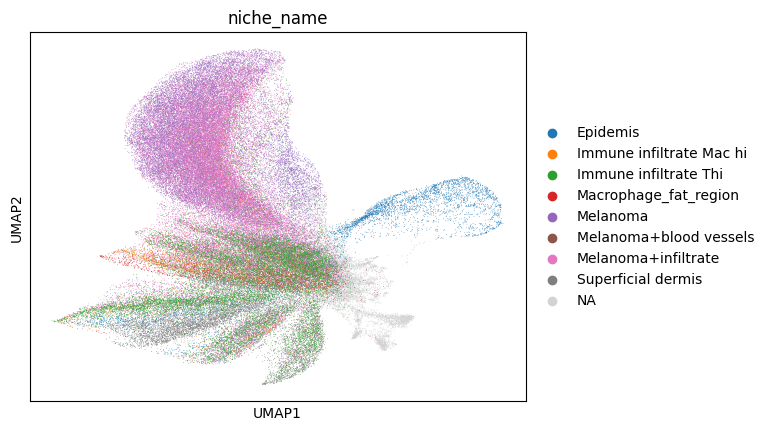

In [19]:
sc.pl.umap(adata, color='niche_name')

In [37]:
scales_counts = sc.pp.normalize_total(adata, target_sum=None, inplace=False)
adata.X = sc.pp.log1p(scales_counts["X"], copy=True)
sc.pp.pca(adata, svd_solver="arpack", use_highly_variable=False)
sc.pp.neighbors(adata)
sc.tl.umap(adata)

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


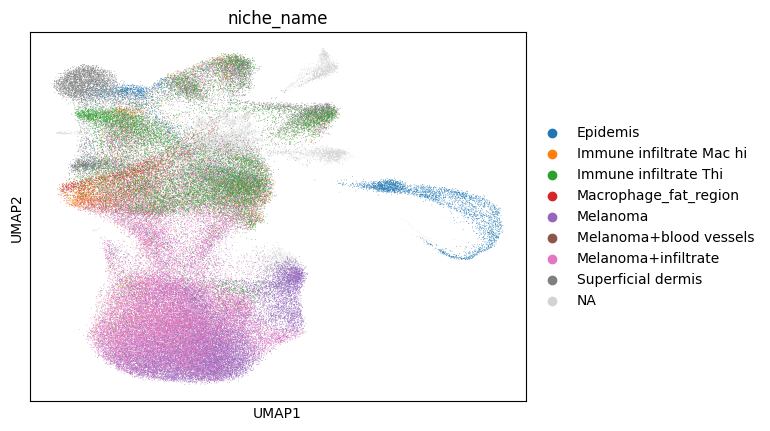

In [38]:
sc.pl.umap(adata, color='niche_name')

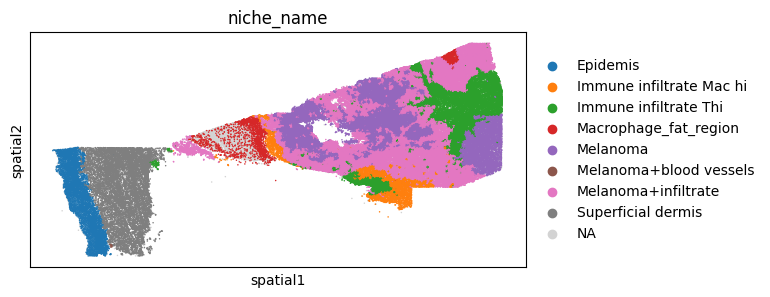

In [43]:
sc.pl.spatial(adata,
              color='niche_name',
              spot_size=30)

In [39]:
adata.obs['niche_name'].value_counts()

Melanoma+infiltrate         36917
Melanoma                    22630
Immune infiltrate Thi       16186
Superficial dermis          11195
Epidemis                     5390
Immune infiltrate Mac hi     4200
Macrophage_fat_region        2219
Melanoma+blood vessels         12
Name: niche_name, dtype: int64

In [42]:
5 * 512

2560

In [40]:
sc.pp.calculate_qc_metrics(
    adata,
    inplace=True
)

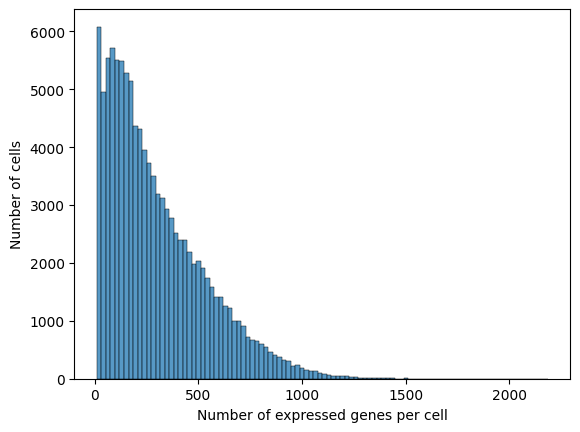

In [41]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(data=adata.obs, x='n_genes_by_counts', bins=100)
plt.xlabel('Number of expressed genes per cell')
plt.ylabel('Number of cells')
plt.show()

In [5]:
adata.obsm['spatial_connectivities']

KeyError: 'spatial_connectivities'

In [ ]:
# Load hold out skin samples and concatenate in one adata object
adata_list = []

for subdir, _, files in os.walk('/lustre/scratch126/cellgen/team361/DATASETS/silver/xhs1000-39b_1p'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad'):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)
            print(adata.X)
            adata.X = adata.X.astype(int64)
            print(adata.X)

adata = ad.concat(adata_list, join='outer', index_unique=None)

In [ ]:
adata.X

In [ ]:
adata.obsp

In [ ]:
adata2 = sc.read_h5ad('/lustre/scratch126/cellgen/team361/DATASETS/silver/mmb0-1b_smb1-1b_1p/harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad')

In [3]:
import pickle

# Path to your pickle file
pickle_file_path = '/lustre/scratch126/cellgen/team361/DATASETS/tokenizer/cell-graph-tokenizer/human_cohort1_10m/token_dictionary.pkl'

# Load the pickle file
with open(pickle_file_path, 'rb') as file:
    token_dict = pickle.load(file)

# Now `token_dict` is a Python dictionary
print(token_dict)

{'<pad>': 0, '<mask>': 1, '<cls_0>': 2, '<cls_1>': 3, '<cls_2>': 4, '<cls_3>': 5, '<cls_4>': 6, '<cls_5>': 7, '<cls_6>': 8, '<cls_7>': 9, '<cls_8>': 10, '<cls_9>': 11, '<cls_10>': 12, '<cls_11>': 13, '<cls_12>': 14, '<cls_13>': 15, '<cls_14>': 16, '<cls_15>': 17, '<cls_16>': 18, '<cls_17>': 19, '<cls_18>': 20, '<cls_19>': 21, '<cls_20>': 22, '<cls_21>': 23, '<cls_22>': 24, '<cls_23>': 25, '<cls_24>': 26, '<cls_25>': 27, '<cls_26>': 28, '<cls_27>': 29, '<cls_28>': 30, '<cls_29>': 31, '<cls_30>': 32, '<cls_31>': 33, '<cls_32>': 34, '<cls_33>': 35, '<cls_34>': 36, '<cls_35>': 37, '<cls_36>': 38, '<cls_37>': 39, '<cls_38>': 40, '<cls_39>': 41, '<cls_40>': 42, '<cls_41>': 43, '<cls_42>': 44, '<cls_43>': 45, '<cls_44>': 46, '<cls_45>': 47, '<cls_46>': 48, '<cls_47>': 49, '<cls_48>': 50, '<cls_49>': 51, '<cls_50>': 52, '<cls_51>': 53, '<cls_52>': 54, '<cls_53>': 55, '<cls_54>': 56, '<cls_55>': 57, '<cls_56>': 58, '<cls_57>': 59, '<cls_58>': 60, '<cls_59>': 61, '<cls_60>': 62, '<cls_61>': 63, 

In [4]:
spv_count = sum(1 for key in token_dict if "spv" in key)
spv_count

94

In [5]:
len(token_dict)

5813

In [ ]:
import os
import pickle

import scanpy as sc
import squidpy as sq

In [ ]:
folder_path = '/lustre/scratch126/cellgen/team361/DATASETS/silver/xhs1000-39b_1p'
token_dict_path = '/lustre/scratch126/cellgen/team361/DATASETS/tokenizer/cell-neighborhood-tokenizer/xhs1000-39b_1p/token_dictionary.pkl'

In [ ]:
with open(token_dict_path, 'rb') as f:
    token_dict = pickle.load(f)

In [ ]:
len(token_dict)

In [ ]:
count_spv_keys = sum(1 for key in token_dict if key.startswith("spv"))
count_spv_keys

In [ ]:
token_dict[list(token_dict.keys())[-1:][0]]

In [ ]:
token_dict['ENSG00000292373']

In [ ]:
max_nonzero_counts = 0  # Initialize a variable to store the maximum count
neighbor_max_nonzero_counts = 0

# Iterate through all .h5ad files in the folder
for filename in os.listdir(folder_path):
    if filename.endswith('.h5ad'):
        file_path = os.path.join(folder_path, filename)
        
        # Load the .h5ad file
        adata = sc.read_h5ad(file_path)

        sq.gr.spatial_neighbors(adata,
                                coord_type='generic',
                                spatial_key='spatial',
                                delaunay=True,
                                set_diag=True)

        adata.layers['X_neighborhood'] = (
                adata.obsp['spatial_connectivities'].T @ adata.X)
        
        # Calculate nonzero counts per cell
        nonzero_counts = (adata.X > 0).sum(axis=1)
        neighbor_nonzero_counts = (adata.layers['X_neighborhood'] > 0).sum(axis=1)
        
        # Get the maximum nonzero count in the current file
        file_max_nonzero = nonzero_counts.max()
        file_max_neighbor_nonzero = neighbor_nonzero_counts.max()
        
        # Update the overall maximum if the current file has a higher value
        if file_max_nonzero > max_nonzero_counts:
            max_nonzero_counts = file_max_nonzero

        if file_max_neighbor_nonzero > neighbor_max_nonzero_counts:
            neighbor_max_nonzero_counts = file_max_neighbor_nonzero

In [ ]:
adata.obs

In [ ]:
max_nonzero_counts

In [ ]:
neighbor_max_nonzero_counts

In [ ]:
adata_test = sc.read_h5ad('/lustre/scratch126/cellgen/team361/DATASETS/bronze/xhs1000-1b_1p/adata_5k_xenium_skin.h5ad')

In [ ]:
adata_test.obs['info_id']

In [ ]:
batch_mapping_dict = {value: idx for idx, value in enumerate(adata_test.obs['info_id'].unique().tolist())}

In [ ]:
adata_test.obs

In [ ]:
batch_mapping_dict # 19, 11, 32